# H7 · Cuando Stage 2 recibe la respuesta correcta, lo que le impide transportarla es el prompt

**Hipótesis.** Los ~17 puntos que Stage 2 pierde en el brazo B (el ground truth como entrada) no
son un techo del modelo ni de la arquitectura de dos etapas: los causa el prompt de producción,
que no trata las conexiones del World Model como evidencia suficiente.

**Veredicto: se sostiene en el brazo B, y no se traslada a producción.**

- **Brazo B:** con el prompt nuevo (V9) Flash pasa de 83,18 a **100,00** de F1 de aristas: 361 de
  361 aristas, 30 de 30 videos perfectos. Con solo el World Model, también 100,00.
- **Producción (Stage 1 automático):** 57,12 → 57,55 (+0,43, IC 95 % [−1,88, +2,98]). Sin efecto.
- **Brazo A (transcripción manual):** 61,27 → 58,45. Contra la primera corrida de V6 son −2,82
  (IC [−5,53, −0,66]); contra su réplica, −1,95 (IC [−5,44, +1,15]). Entre igual y algo peor.
- **Vale para los tres modelos:** en el brazo B, V9 lleva a Claude de 82,89 a 97,45 y a Pro de
  71,49 a 93,72. Ninguno pierde ya aristas de forma sistemática (0 en Flash y Claude, 9 en Pro);
  lo que les queda a Claude y a Pro son aristas que añaden por su cuenta (15 y 36).
- **No era una regla suelta:** el prompt de producción sin "Unidirectional Default" da 81,86,
  igual que con ella. Lo que hace el trabajo es declarar autoritativas las conexiones.

**Qué significa.** Stage 2 puede transportar todas las flechas que recibe. Fuera del oráculo no
mejora porque las flechas que faltan no vienen en la entrada: no están en la pizarra ni las lee
Stage 1. El prompt era el cuello de botella del brazo B, no del sistema.

## Archivos usados, cómo se generaron y dónde quedaron

| corrida | entrada de Stage 2 | cómo se generó | dónde quedó |
|---|---|---|---|
| V9 · brazo B | World Model oráculo + pizarra + transcript | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v9_connection_ledger.txt --panel 30 --model gemini-3.6-flash --oracle oracle_gt --out …` | `reports/prompt_v9/flash_oracle-gt/` |
| V9 · brazo B, solo World Model | World Model oráculo | `… --oracle oracle_gt --no-transcript --no-image --out …` | `reports/prompt_v9/flash_oracle-gt_solo-wm/` |
| V9 · brazo A | transcripción manual + pizarra + transcript | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v9_connection_ledger.txt --panel 30 --model gemini-3.6-flash --oracle vision --out …` | `reports/prompt_v9/flash_stage1-manual/` |
| V9 · producción | Stage 1 automático cacheado + pizarra + transcript | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v9_connection_ledger.txt --panel 30 --model gemini-3.6-flash --out …` | `reports/prompt_v9/flash_produccion/` |
| V9 · réplicas de Flash | brazo A y producción | los mismos comandos con `--replicate 2` | `reports/prompt_v9/flash_stage1-manual_rep2/`, `flash_produccion_rep2/` |
| V9 · Pro, brazo B | World Model oráculo + pizarra + transcript | `… --prompt stage2_v9_connection_ledger.txt --oracle oracle_gt --model gemini-3.1-pro-preview --out …` | `reports/prompt_v9/pro_oracle-gt/` |
| V9 · Claude, brazo B | la misma | `scripts/ablation/claude_panel.py --oracle oracle_gt --prompt stage2_v9_connection_ledger.txt export`, `run`, `evaluate` | `reports/claude_oracle_gt_v9/` |
| V6 sin una regla · Flash, brazo B | la misma | `… --prompt stage2_v6_no_unidirectional.txt --oracle oracle_gt --out …` | `reports/prompt_v9/flash_oracle-gt_v6-sin-unidireccional/` |
| V6 · referencias | las mismas entradas | ver H1, H2 y H4 | `reports/ablation/*oracle-oracle_gt*`, `reports/pro_vs_flash/flash_gemini-3.6-flash*` |

**El prompt nuevo:** `src/configs/prompts/stage2_v9_connection_ledger.txt` (sha `0ac90b9081d1`),
registrado en `src/configs/prompts/MANIFEST.json`. Es el de producción (`stage2_v6_corrected__cell9.txt`,
sha `ed1d85054d73`) con un cambio de fondo: las `visual_connections` del World Model pasan a ser
autoritativas.

- **Bloque nuevo "Connection Ledger":** una arista por conexión listada; se conservan los dos
  sentidos y los pares repetidos; fusionar nodos no borra aristas; el audio asigna flujo,
  secuencia y tipo pero no elimina; autochequeo del conteo.
- **Dos reglas reescritas** porque lo contradecían: "Unidirectional Default" y "Visual & Verbal Grounding".
- Todo lo demás es idéntico, incluidas la expansión por audio y la poda.

Las comparaciones pareadas de V9 contra V6 están en `reports/prompt_v9/*/comparacion.md`
(de `scripts/ablation/compare_models.py`). Figuras de este notebook: `hipotesis/figuras/H7_*.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import comun as c

c.estilo()
import json
from collections import Counter

COND = [("B", "Brazo B\nground truth"), ("Bwm", "Brazo B\nsolo World Model"),
        ("A", "Brazo A\ntranscripción manual"), ("P", "Producción\nStage 1 automático")]
TODAS7 = [f"{p}{s}_flash" for p, _ in COND for s in ("", "9")]
n, distintas = c.verificar(TODAS7)
print(f"Control: el F1 de aristas recalculado aquí coincide con el del evaluador en {n - distintas} de {n} filas.")
t = c.tabla_resumen(TODAS7)
for fila, k in zip(t.filas, TODAS7):
    fila[0] = dict(COND)[k.split("_")[0].rstrip("9")].replace("\n", " · ") + (" · V9" if "9_" in k else " · V6")
t

Control: el F1 de aristas recalculado aquí coincide con el del evaluador en 240 de 240 filas.


corrida,F1 servicios,F1 aristas,aristas / GT,faltan,sobran,precisión,recall,servicios inventados,videos perfectos,carpeta
Brazo B · ground truth · V6,99.70,83.18,10.00 / 12.03,86,25,91.7,76.2,1,3,reports/ablation/2026-08-28_0315_STAGE2_V6_CORRECTED_cell9_p30_oracle-oracle_gt
Brazo B · ground truth · V9,99.74,100.00,12.03 / 12.03,0,0,100.0,100.0,0,30,reports/prompt_v9/flash_oracle-gt
Brazo B · solo World Model · V6,99.27,83.35,9.20 / 12.03,97,12,95.7,73.1,0,7,reports/pro_vs_flash/flash_gemini-3.6-flash_oracle-gt_solo-wm
Brazo B · solo World Model · V9,99.44,100.00,12.03 / 12.03,0,0,100.0,100.0,0,30,reports/prompt_v9/flash_oracle-gt_solo-wm
Brazo A · transcripción manual · V6,87.82,61.27,9.00 / 12.03,170,79,70.7,52.9,29,0,reports/pro_vs_flash/flash_gemini-3.6-flash_stage1-manual
Brazo A · transcripción manual · V9,87.78,58.45,8.83 / 12.03,180,84,68.3,50.1,28,0,reports/prompt_v9/flash_stage1-manual
Producción · Stage 1 automático · V6,85.90,57.12,9.03 / 12.03,184,94,65.3,49.0,29,0,reports/pro_vs_flash/flash_gemini-3.6-flash
Producción · Stage 1 automático · V9,85.65,57.55,8.83 / 12.03,184,88,66.8,49.0,31,0,reports/prompt_v9/flash_produccion


## 1 · Por qué se perdían las aristas con el prompt de producción

Cada arista del ground truth que falta en la salida de Flash (brazo B, prompt V6), clasificada
por lo que se ve en la salida.

Nodos: 263 generados de 262 en la referencia. Flash no fusiona ni poda.
World Model oráculo: 355 de 361 conexiones llegan con la descripción vacía.


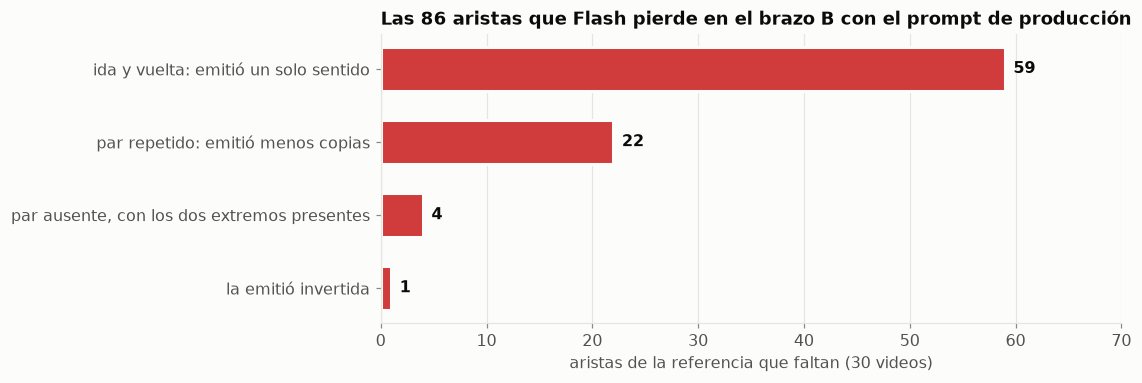

In [2]:
def mecanismos(clave):
    m = Counter()
    for vid, f in c.filas(clave).items():
        e_gt, e_gen = c.gt(vid)[1], c.gen(f)
        servicios = {x["service"] for x in f["analysis"]["nodes"]}
        for (a, b), n_ in (e_gt - e_gen).items():
            if a not in servicios or b not in servicios:
                m["un extremo no existe en la salida"] += n_
            elif e_gen[(a, b)] > 0:
                m["par repetido: emitió menos copias"] += n_
            elif e_gen[(b, a)] > 0 and e_gt[(b, a)] > 0:
                m["ida y vuelta: emitió un solo sentido"] += n_
            elif e_gen[(b, a)] > e_gt[(b, a)]:
                m["la emitió invertida"] += n_
            else:
                m["par ausente, con los dos extremos presentes"] += n_
    return m

m6 = mecanismos("B_flash")
nodos_gt = sum(f["gt_nodes"] for f in c.filas("B_flash").values())
nodos_gen = sum(f["gen_nodes"] for f in c.filas("B_flash").values())
vacias = total = 0
for vid in c.filas("B_flash"):
    sin_nota, n_ = c.aristas_gt_sin_nota(vid)   # la conversión copia la nota del GT como descripción
    vacias, total = vacias + sin_nota, total + n_
print(f"Nodos: {nodos_gen} generados de {nodos_gt} en la referencia. Flash no fusiona ni poda.")
print(f"World Model oráculo: {vacias} de {total} conexiones llegan con la descripción vacía.")

orden = sorted(m6, key=m6.get)
fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.barh(orden, [m6[k] for k in orden], height=0.6, color=c.FALTA, edgecolor=c.FONDO, linewidth=2)
for y, k in enumerate(orden):
    ax.text(m6[k] + 0.8, y, str(m6[k]), va="center", fontweight="bold")
ax.set_xlim(0, 70)
ax.set_xlabel("aristas de la referencia que faltan (30 videos)")
ax.set_title(f"Las {sum(m6.values())} aristas que Flash pierde en el brazo B con el prompt de producción")
ax.grid(axis="y", visible=False)
fig.tight_layout()
c.guardar(fig, "H7_mecanismo")

El World Model trae `A → B` y `B → A` sin explicación, y el prompt de producción pide que la
evidencia de cada arista venga de las flechas o del transcript y que todo flujo se trate como
unidireccional salvo que el sentido inverso esté explícito. Flash conserva el sentido que el audio
narra y descarta el otro.

## 2 · El prompt nuevo en las cuatro condiciones

Color claro: prompt de producción (V6). Color pleno: prompt nuevo (V9).

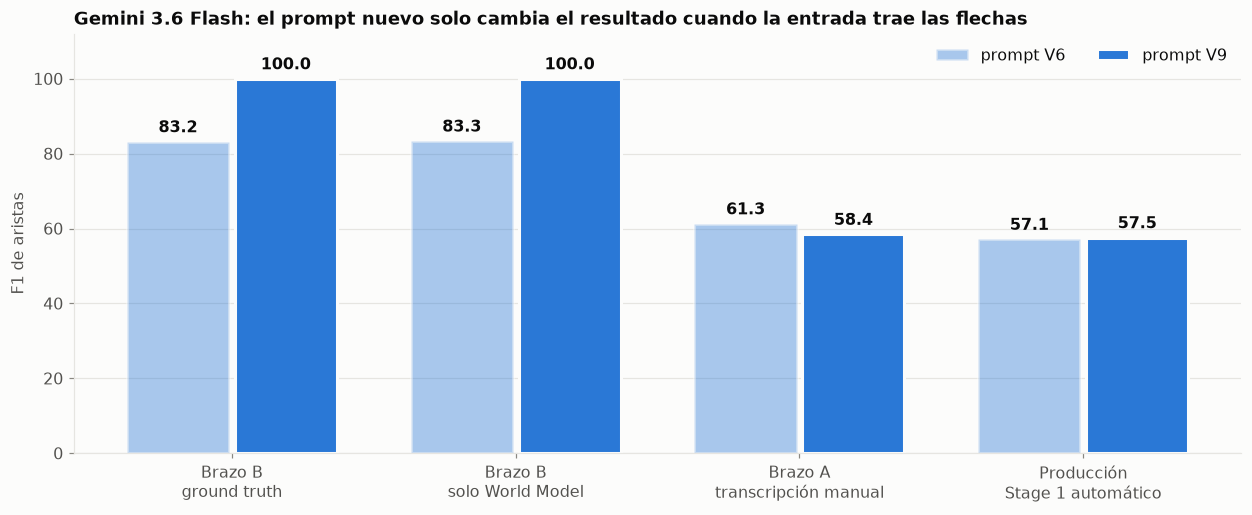

In [3]:
fig, ax = plt.subplots(figsize=(11.5, 4.8))
for x, (p, nombre) in enumerate(COND):
    for dx, suf, alfa, txt in ((-0.19, "", 0.4, "V6"), (0.19, "9", 1.0, "V9")):
        v = c.resumen(f"{p}{suf}_flash")["edge"]
        ax.bar(x + dx, v, width=0.36, color=c.COLOR["flash"], alpha=alfa, edgecolor=c.FONDO, linewidth=2,
               label=f"prompt {txt}" if x == 0 else None)
        ax.text(x + dx, v + 1.5, f"{v:.1f}", ha="center", va="bottom", fontweight="bold")
ax.set_xticks(range(len(COND)), [n_ for _, n_ in COND])
ax.set_ylim(0, 112)
ax.set_ylabel("F1 de aristas")
ax.set_title("Gemini 3.6 Flash: el prompt nuevo solo cambia el resultado cuando la entrada trae las flechas")
ax.legend(loc="upper right", ncol=2)
ax.grid(axis="x", visible=False)
fig.tight_layout()
c.guardar(fig, "H7_cuatro_condiciones")

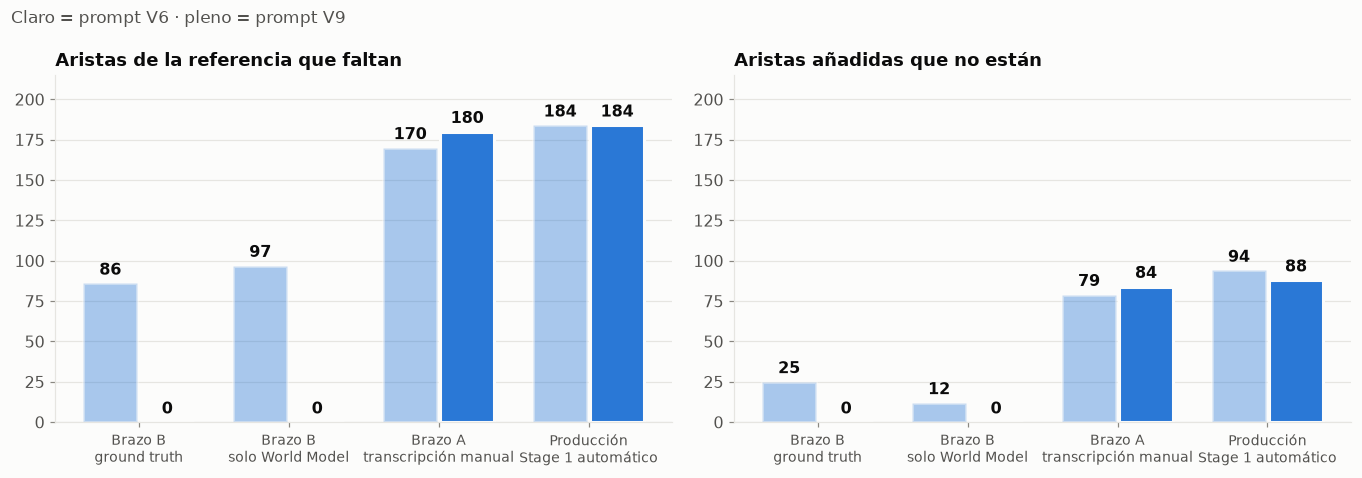

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
for a, campo, titulo in ((ax[0], "faltan", "Aristas de la referencia que faltan"), (ax[1], "sobran", "Aristas añadidas que no están")):
    for x, (p, nombre) in enumerate(COND):
        for dx, suf, alfa in ((-0.19, "", 0.4), (0.19, "9", 1.0)):
            v = c.resumen(f"{p}{suf}_flash")[campo]
            a.bar(x + dx, v, width=0.36, color=c.COLOR["flash"], alpha=alfa, edgecolor=c.FONDO, linewidth=2)
            a.text(x + dx, v + 3, str(v), ha="center", va="bottom", fontweight="bold")
    a.set_xticks(range(len(COND)), [n_ for _, n_ in COND], fontsize=9)
    a.set_ylim(0, 215)
    a.set_title(titulo)
    a.grid(axis="x", visible=False)
fig.suptitle("Claro = prompt V6 · pleno = prompt V9", x=0.01, ha="left", fontsize=11, color=c.TINTA2)
fig.tight_layout()
c.guardar(fig, "H7_faltan_y_sobran")

## 3 · Fuera del oráculo, video por video

Diferencia pareada V9 − V6 sobre los mismos 30 videos y el mismo Stage 1. La franja gris es el MDE del paper.

comparación (B − A),Δ,IC 95 %,gana / pierde / empata,p (signos)
Brazo A · V9 − V6,-2.82,"[-5.53, -0.66]",4 / 9 / 17,0.267
Producción · V9 − V6,+0.43,"[-1.88, +2.98]",6 / 7 / 17,1.000
Brazo A · V6 réplica − V6 (ruido),-0.87,"[-2.77, +0.83]",3 / 5 / 22,0.727


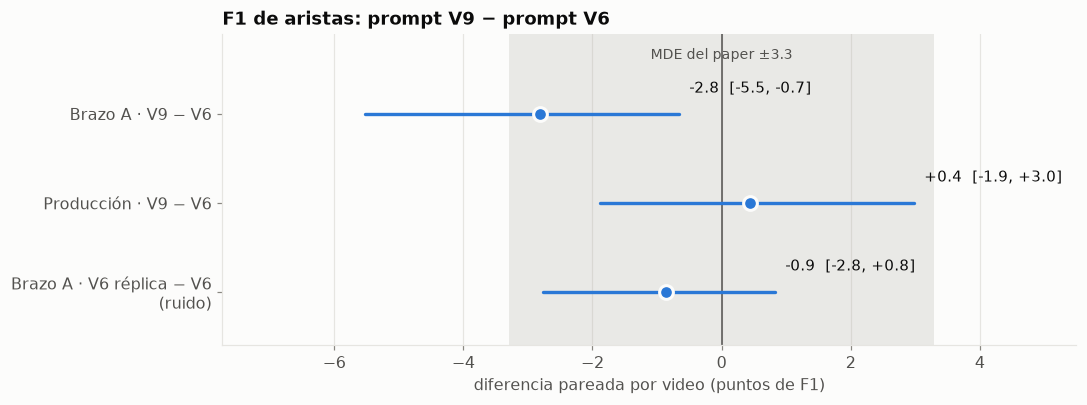

In [5]:
pares = [("A_flash", "A9_flash"), ("P_flash", "P9_flash"), ("A_flash", "A_flash_rep2")]
fig, ax = plt.subplots(figsize=(10, 3.8))
c.bosque(ax, pares, titulo="F1 de aristas: prompt V9 − prompt V6", banda=3.29, banda_txt="MDE del paper")
ax.set_yticks(range(3), ["Brazo A · V6 réplica − V6\n(ruido)", "Producción · V9 − V6", "Brazo A · V9 − V6"])
fig.tight_layout()
c.guardar(fig, "H7_diferencias")
t = c.tabla_pareada(pares)
for fila, txt in zip(t.filas, ["Brazo A · V9 − V6", "Producción · V9 − V6", "Brazo A · V6 réplica − V6 (ruido)"]):
    fila[0] = txt
t

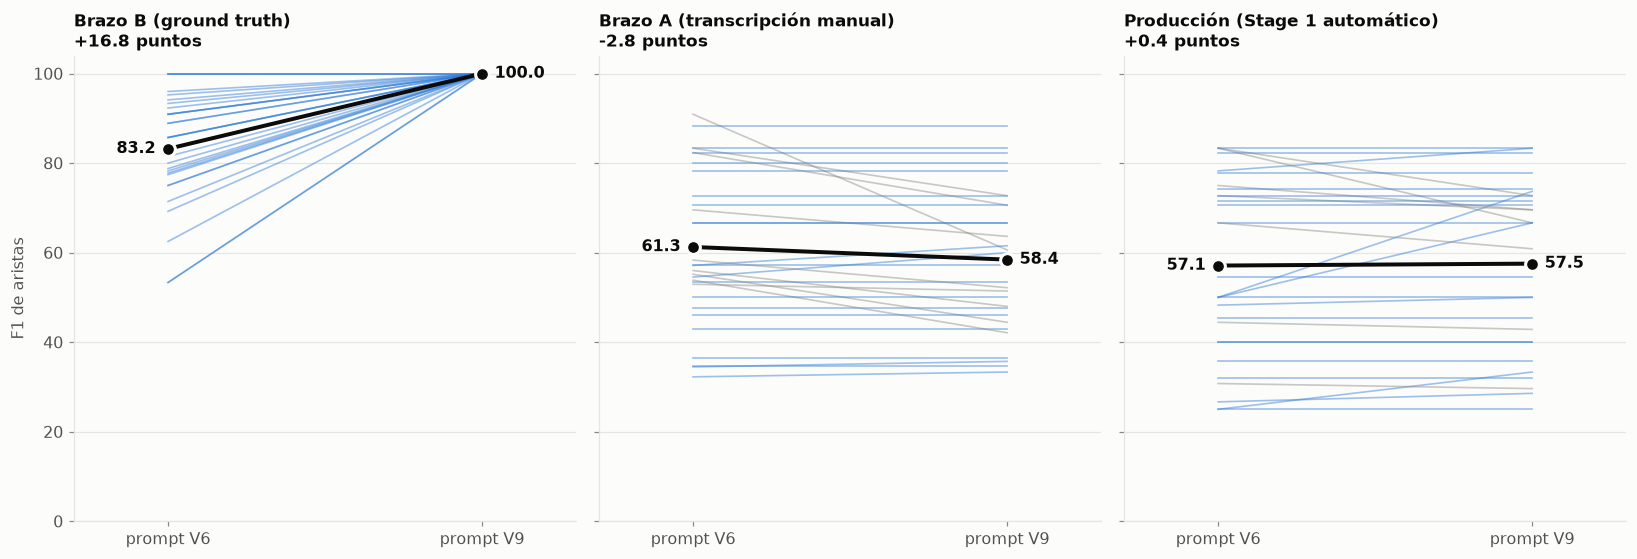

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
c.pendientes(ax[0], "B_flash", "B9_flash", nombres=("prompt V6", "prompt V9"))
c.pendientes(ax[1], "A_flash", "A9_flash", nombres=("prompt V6", "prompt V9"))
c.pendientes(ax[2], "P_flash", "P9_flash", nombres=("prompt V6", "prompt V9"))
for a, nombre, (k6, k9) in zip(ax, ["Brazo B (ground truth)", "Brazo A (transcripción manual)", "Producción (Stage 1 automático)"],
                               [("B_flash", "B9_flash"), ("A_flash", "A9_flash"), ("P_flash", "P9_flash")]):
    a.set_title(f"{nombre}\n{c.resumen(k9)['edge'] - c.resumen(k6)['edge']:+.1f} puntos", fontsize=11)
ax[0].set_ylabel("F1 de aristas")
fig.tight_layout()
c.guardar(fig, "H7_pendientes")

## 4 · Los tres modelos en el brazo B

Color claro: prompt de producción (V6). Color pleno: prompt nuevo (V9).

comparación (B − A),Δ,IC 95 %,gana / pierde / empata,p (signos)
Gemini 3.6 Flash − Gemini 3.6 Flash,+16.82,"[+12.65, +21.38]",27 / 0 / 3,0.000
Claude Opus 5.5 − Claude Opus 5.5,+14.56,"[+9.87, +19.74]",23 / 1 / 6,0.000
Gemini 3.1 Pro − Gemini 3.1 Pro,+22.24,"[+15.47, +29.54]",27 / 2 / 1,0.000
Claude Opus 5.5 − Gemini 3.6 Flash,-2.55,"[-4.39, -1.00]",0 / 8 / 22,0.008
Gemini 3.1 Pro − Gemini 3.6 Flash,-6.28,"[-10.38, -2.95]",0 / 13 / 17,0.000


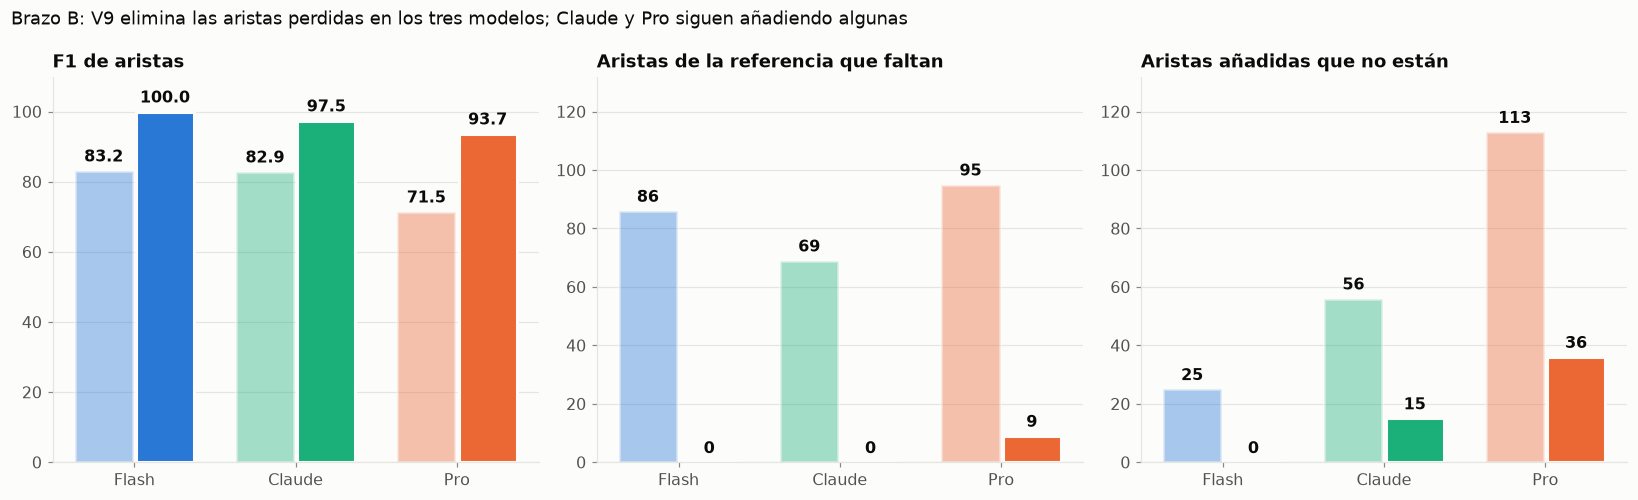

In [7]:
M3 = ["flash", "claude", "pro"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, campo, titulo, ymax in ((ax[0], "edge", "F1 de aristas", 100), (ax[1], "faltan", "Aristas de la referencia que faltan", 120),
                               (ax[2], "sobran", "Aristas añadidas que no están", 120)):
    for x, m in enumerate(M3):
        for dx, pref, alfa in ((-0.19, "B", 0.4), (0.19, "B9", 1.0)):
            v = c.resumen(f"{pref}_{m}")[campo]
            a.bar(x + dx, v, width=0.36, color=c.COLOR[m], alpha=alfa, edgecolor=c.FONDO, linewidth=2)
            a.text(x + dx, v + ymax * 0.015, str(v) if isinstance(v, int) else f"{v:.1f}", ha="center", va="bottom", fontweight="bold")
    a.set_xticks(range(3), [m.capitalize() for m in M3])
    a.set_ylim(0, ymax * 1.1)
    a.set_title(titulo)
    a.grid(axis="x", visible=False)
fig.suptitle("Brazo B: V9 elimina las aristas perdidas en los tres modelos; Claude y Pro siguen añadiendo algunas", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
c.guardar(fig, "H7_tres_modelos")
c.tabla_pareada([("B_flash", "B9_flash"), ("B_claude", "B9_claude"), ("B_pro", "B9_pro"), ("B9_flash", "B9_claude"), ("B9_flash", "B9_pro")])

Las filas 1 a 3 de la tabla son V9 − V6 del mismo modelo; las dos últimas comparan a Claude y a
Pro contra Flash, los tres con V9.

## 5 · Réplicas y la regla suelta

Arriba, el prompt de producción sin "Unidirectional Default" contra el prompt intacto (brazo B).
Abajo, V9 contra V6 fuera del oráculo, con las dos corridas de cada lado.

Las dos corridas de V9 en el brazo A producen las mismas aristas en 30 de 30 videos.


comparación (B − A),Δ,IC 95 %,gana / pierde / empata,p (signos)
Brazo B · V6 sin la regla − V6,-1.33,"[-3.47, +0.63]",8 / 7 / 15,1.000
Brazo B · V6 réplica − V6 (ruido),-2.02,"[-4.36, +0.13]",6 / 14 / 10,0.115
Brazo A · V9 réplica − V6,-2.82,"[-5.53, -0.66]",4 / 9 / 17,0.267
Brazo A · V9 réplica − V6 réplica,-1.95,"[-5.44, +1.15]",6 / 8 / 16,0.791
Producción · V9 − V6,+0.43,"[-1.88, +2.98]",6 / 7 / 17,1.000
Producción · V9 réplica − V6,+0.03,"[-1.40, +1.64]",5 / 6 / 19,1.000


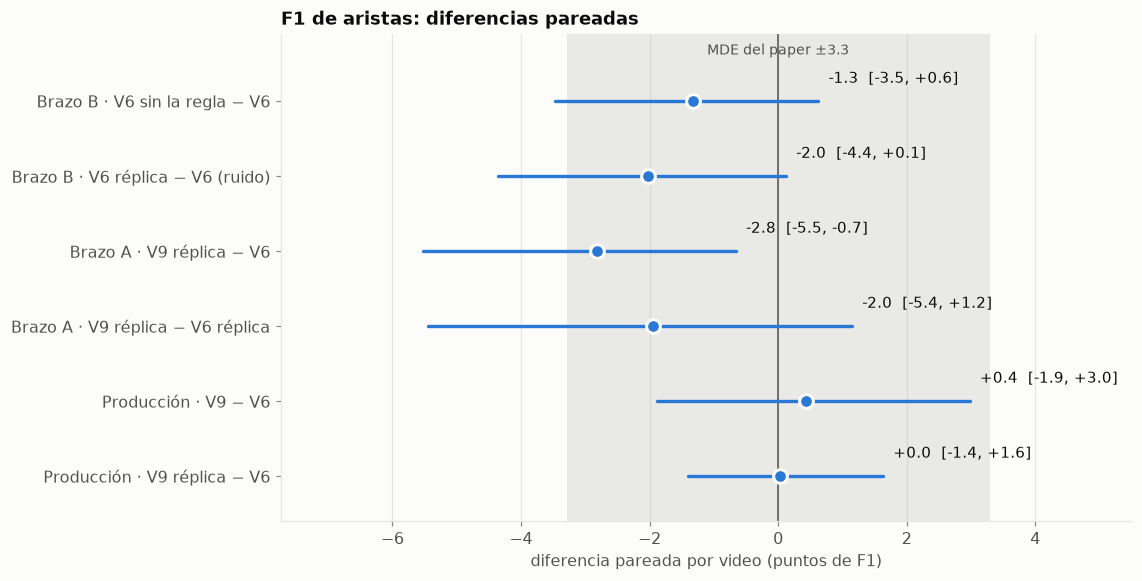

In [8]:
pares = [("B_flash", "Bu_flash"), ("B_flash", "B_flash_rep2"),
         ("A_flash", "A9_flash_rep2"), ("A_flash_rep2", "A9_flash_rep2"),
         ("P_flash", "P9_flash"), ("P_flash", "P9_flash_rep2")]
nombres = ["Brazo B · V6 sin la regla − V6", "Brazo B · V6 réplica − V6 (ruido)",
           "Brazo A · V9 réplica − V6", "Brazo A · V9 réplica − V6 réplica",
           "Producción · V9 − V6", "Producción · V9 réplica − V6"]
fig, ax = plt.subplots(figsize=(10.5, 5.4))
c.bosque(ax, pares, titulo="F1 de aristas: diferencias pareadas", banda=3.29, banda_txt="MDE del paper")
ax.set_yticks(range(len(pares)), nombres[::-1])
fig.tight_layout()
c.guardar(fig, "H7_replicas_y_regla_suelta")
iguales = sum(c.gen(c.filas("A9_flash")[v]) == c.gen(c.filas("A9_flash_rep2")[v]) for v in c.filas("A9_flash"))
print(f"Las dos corridas de V9 en el brazo A producen las mismas aristas en {iguales} de 30 videos.")
t = c.tabla_pareada(pares)
for fila, txt in zip(t.filas, nombres):
    fila[0] = txt
t

## 6 · Un video de ejemplo en el brazo B

La entrada de Stage 2 es el ground truth. Con el prompt de producción se pierden los retornos
(rojo punteado); con el nuevo, la salida es la entrada.

6YkguepAQuQ: +46.7 puntos de F1 de aristas al cambiar de prompt


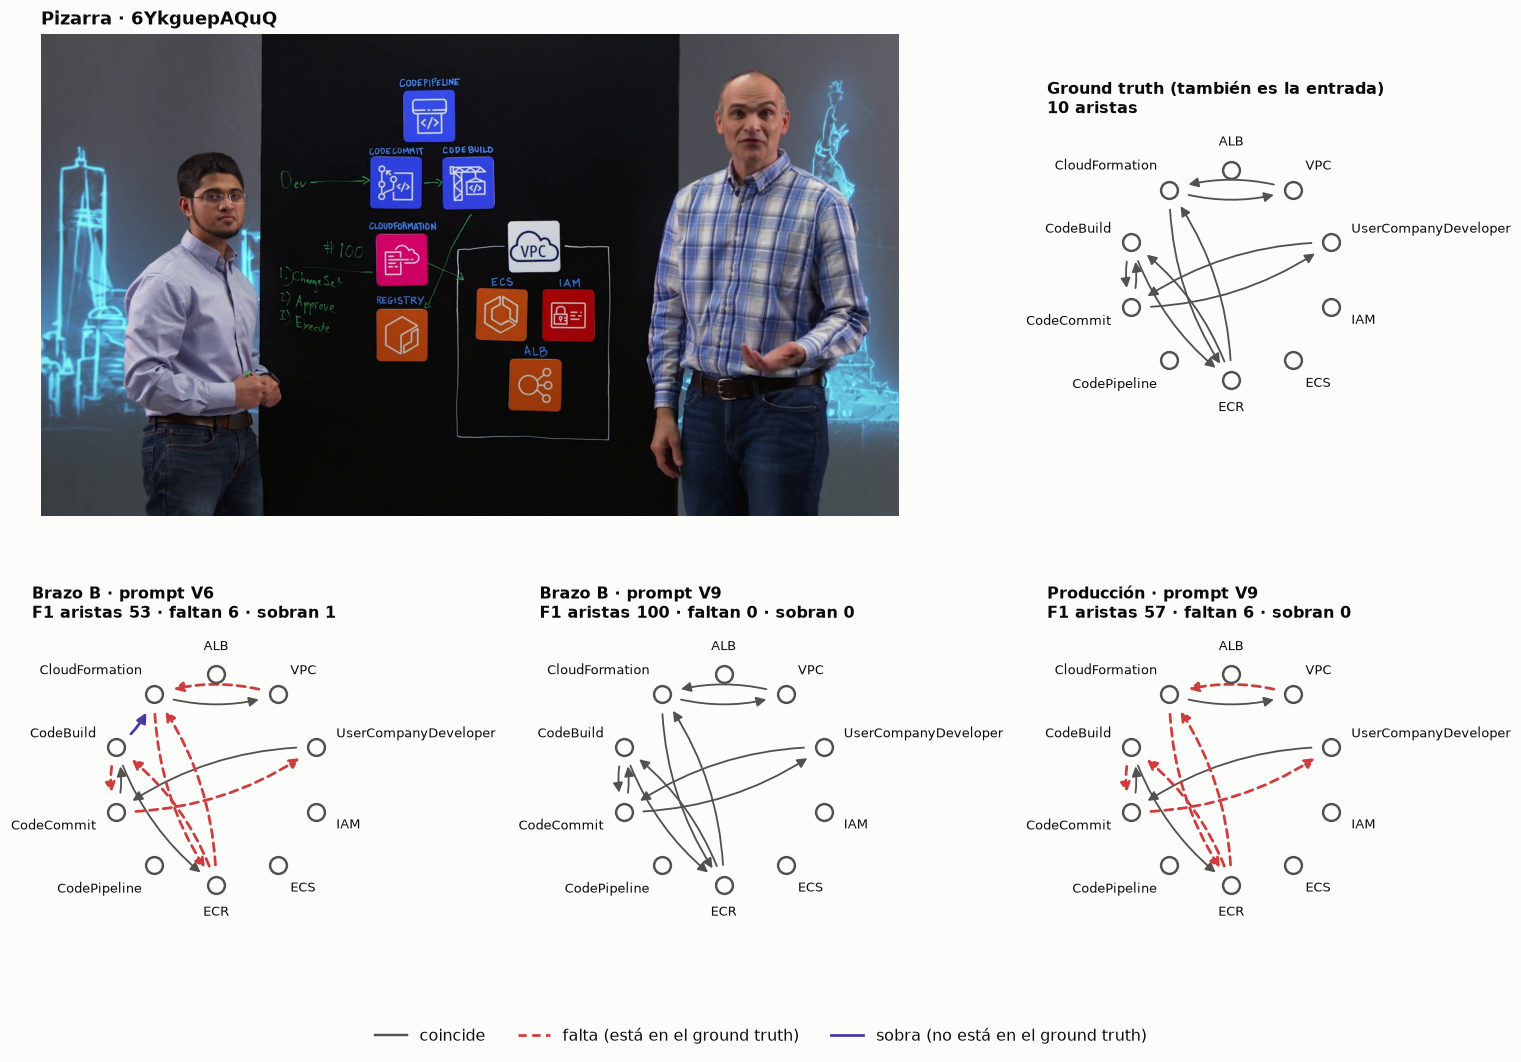

In [9]:
d = c.pareado("B_flash", "B9_flash")["d"]
vid = max(d, key=d.get)
print(f"{vid}: {d[vid]:+.1f} puntos de F1 de aristas al cambiar de prompt")
fig = plt.figure(figsize=(14, 9.5))
gs = fig.add_gridspec(2, 3)
c.pizarra(fig.add_subplot(gs[0, :2]), vid)
c.grafo(fig.add_subplot(gs[0, 2]), vid, titulo="Ground truth (también es la entrada)")
c.grafo(fig.add_subplot(gs[1, 0]), vid, c.filas("B_flash")[vid], "Brazo B · prompt V6")
c.grafo(fig.add_subplot(gs[1, 1]), vid, c.filas("B9_flash")[vid], "Brazo B · prompt V9")
c.grafo(fig.add_subplot(gs[1, 2]), vid, c.filas("P9_flash")[vid], "Producción · prompt V9")
c.leyenda_grafo(fig)
fig.tight_layout()
c.guardar(fig, "H7_ejemplo")

## Qué aporta al paper

- **La Tabla VII cambia.** Los 17,83 puntos atribuidos a "pérdida propia de la segunda etapa" no
  marcan un techo de la arquitectura: desaparecen con un cambio de prompt. Lo que hay que decir es
  que el prompt de producción descarta las conexiones del World Model que no puede justificar con el audio.
- **La tesis del título sale reforzada.** En producción V9 es la duodécima variante que no mueve el
  resultado (+0,43), y ahora con explicación: Stage 2 transporta lo que recibe; las flechas que
  faltan no vienen en la entrada.
- **Hay una tensión que reportar.** Hacer autoritativo el World Model ayuda cuando la entrada es
  perfecta y cuesta ~3 puntos cuando es una lectura humana incompleta, porque el audio aportaba
  algunas aristas correctas que V9 ya no deja añadir con la misma libertad.

- **Los modelos más fuertes siguen añadiendo.** Con V9, Claude queda 2,55 puntos por debajo de Flash
  (IC [−4,39, −1,00]) y Pro 6,28 (IC [−10,38, −2,95]), solo por aristas de más que toman del audio.
  Es el mismo comportamiento de H5, reducido.

**Salvedades.** V9 tiene dos corridas con Flash en el brazo A y en producción, y una sola en el
resto de condiciones y con Pro y Claude. A Claude no se le puede fijar la temperatura. De las tres
piezas de V9 solo se aisló una (la regla "Unidirectional Default", que sola no explica nada); no se
probó el bloque nuevo sin reescribir las otras dos reglas.